John S. Anvik, 2025  
University of Lethbridge Student ID: 001224816

In [1]:
library(tidyverse)

── Attaching core tidyverse packages ──────────────────────── tidyverse 2.0.0 ──
✔ dplyr     1.1.4     ✔ readr     2.1.6
✔ forcats   1.0.1     ✔ stringr   1.6.0
✔ ggplot2   4.0.1     ✔ tibble    3.3.0
✔ lubridate 1.9.4     ✔ tidyr     1.3.1
✔ purrr     1.2.0     
── Conflicts ────────────────────────────────────────── tidyverse_conflicts() ──
✖ dplyr::filter() masks stats::filter()
✖ dplyr::lag()    masks stats::lag()
ℹ Use the conflicted package (<http://conflicted.r-lib.org/>) to force all conflicts to become errors


In [2]:
folder_path <- "C:\\Users\\johna\\OneDrive\\Documents\\Birdsong\\data\\by_id"
files = list.files(folder_path, full.names=TRUE)

data_list <- list()
for (file in files) {
    data_list <- append(data_list, list(read_csv(file)))
}

focal_ids <- list()
for (i in seq_along(data_list)) {
    id <- data_list[[i]] %>% pull(ID) %>% unique()
    # print(id)
    focal_ids[[id]] <- id
}
names(data_list) <- focal_ids

Rows: 2169 Columns: 345
── Column specification ────────────────────────────────────────────────────────
Delimiter: ","
chr    (2): ID, attention_target_id
dbl  (342): UST, time_rel_sunrise, D_M1_M2, D_M1_M3, D_M1_M4, D_M1_M5, D_M1_...
dttm   (1): DateTime

ℹ Use `spec()` to retrieve the full column specification for this data.
ℹ Specify the column types or set `show_col_types = FALSE` to quiet this message.
Rows: 556 Columns: 347
── Column specification ────────────────────────────────────────────────────────
Delimiter: ","
chr    (2): ID, attention_target_id
dbl  (344): UST, time_rel_sunrise, D_M1_M2, D_M1_M3, D_M1_M4, D_M1_M5, D_M1_...
dttm   (1): DateTime

ℹ Use `spec()` to retrieve the full column specification for this data.
ℹ Specify the column types or set `show_col_types = FALSE` to quiet this message.
Rows: 1033 Columns: 347
── Column specification ────────────────────────────────────────────────────────
Delimiter: ","
chr    (2): ID, attention_target_id
dbl  (344): UST, time

In [25]:
unique(as.Date(data_list[['LbOW']]$DateTime))

[1] "2022-05-13" "2022-05-14" "2022-05-16" "2022-05-17" "2022-05-18"

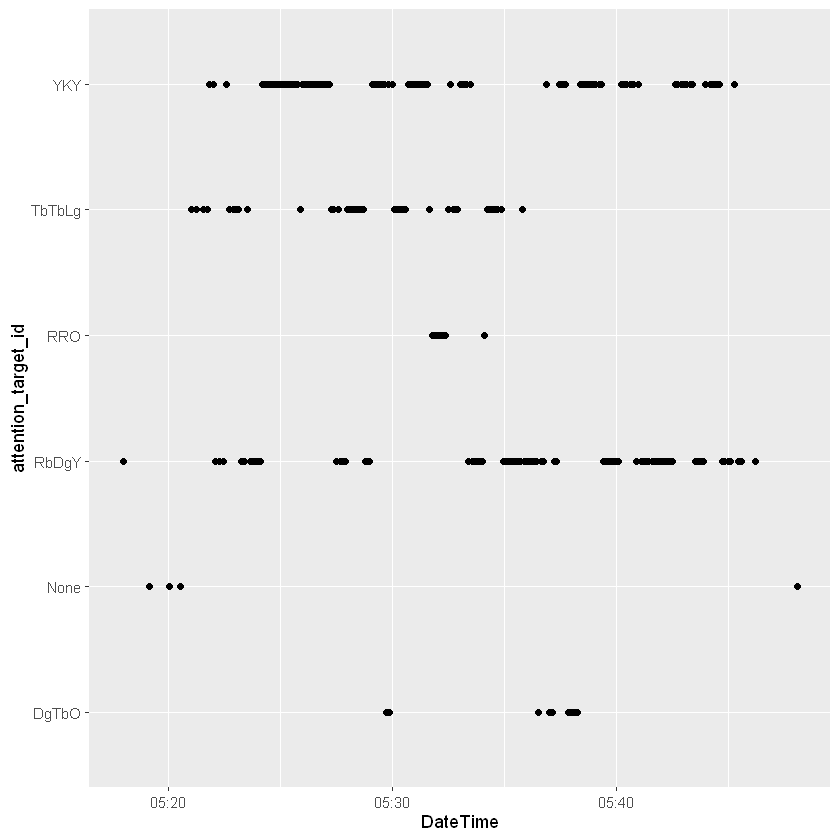

In [4]:
ggplot(data_list[['LbOW']] %>% filter(as.Date(DateTime) == "2022-05-18")) +
    aes(x=DateTime, y=attention_target_id) +
    geom_point()

Don't know how to automatically pick scale for object of type
<spec_tbl_df/tbl_df/tbl/data.frame>. Defaulting to continuous.
Don't know how to automatically pick scale for object of type
<spec_tbl_df/tbl_df/tbl/data.frame>. Defaulting to continuous.
Don't know how to automatically pick scale for object of type
<spec_tbl_df/tbl_df/tbl/data.frame>. Defaulting to continuous.
Don't know how to automatically pick scale for object of type
<spec_tbl_df/tbl_df/tbl/data.frame>. Defaulting to continuous.
Don't know how to automatically pick scale for object of type
<spec_tbl_df/tbl_df/tbl/data.frame>. Defaulting to continuous.
Don't know how to automatically pick scale for object of type
<spec_tbl_df/tbl_df/tbl/data.frame>. Defaulting to continuous.
Don't know how to automatically pick scale for object of type
<spec_tbl_df/tbl_df/tbl/data.frame>. Defaulting to continuous.
Don't know how to automatically pick scale for object of type
<spec_tbl_df/tbl_df/tbl/data.frame>. Defaulting to continuous.


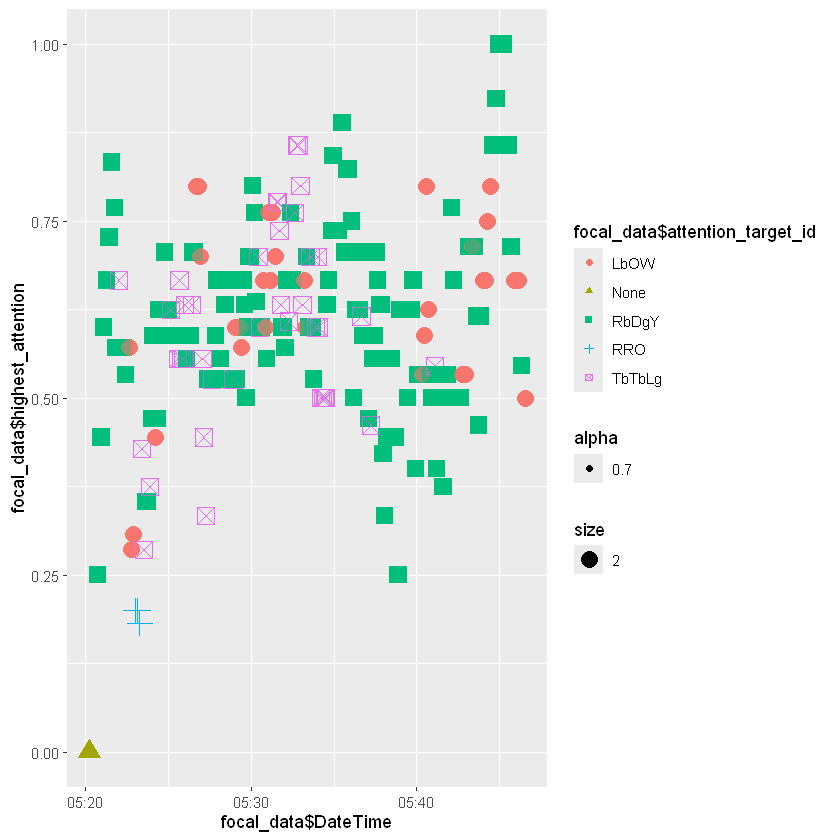

In [9]:
plt <- ggplot()
for (id in focal_ids) {
    focal_data <- data_list[[id]] %>% filter(as.Date(DateTime) == "2022-05-18")
    plt <- plt + aes(data=focal_data, x=focal_data$DateTime, y=focal_data$highest_attention, color=focal_data$attention_target_id, shape=focal_data$attention_target_id, size=2, alpha=0.7) +
    geom_point()
}
plt

[1] "DgTbO"
[1] "KLgK"
[1] "KRDg"
[1] "LbOW"
[1] "OPR"
[1] "RbDgY"
[1] "RRO"
[1] "TbTbLg"
[1] "TbWY"
[1] "WLpTb"
[1] "YKY"
[1] "DgTbO"
[1] "KLgK"
[1] "KRDg"
[1] "LbOW"
[1] "OPR"
[1] "RbDgY"
[1] "RRO"
[1] "TbTbLg"
[1] "TbWY"
[1] "WLpTb"
[1] "YKY"


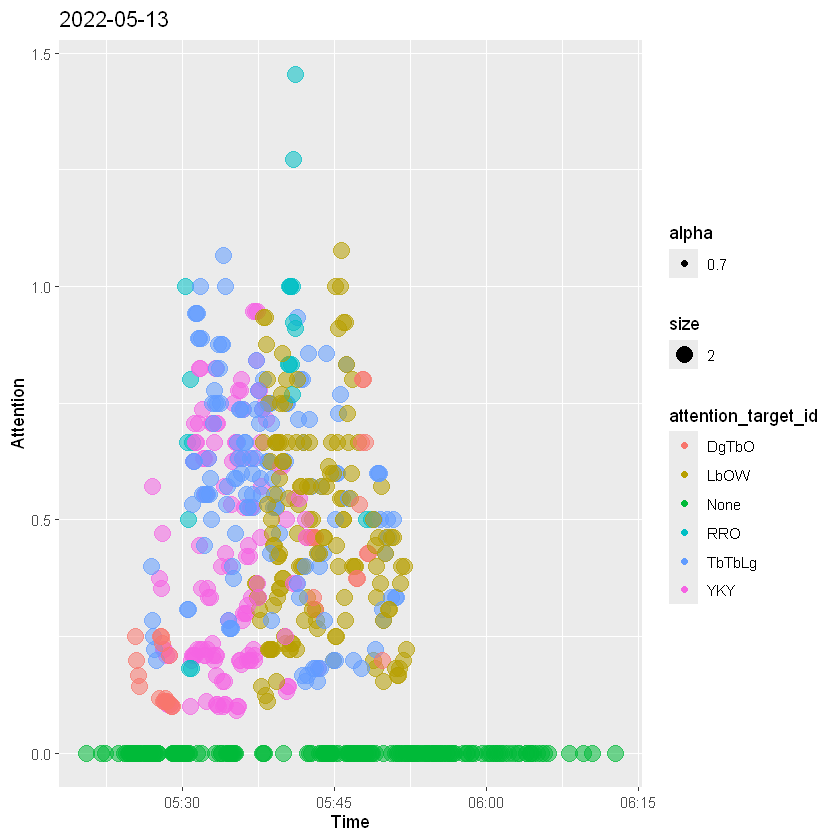

[1] "DgTbO"
[1] "KLgK"
[1] "KRDg"
[1] "LbOW"
[1] "OPR"
[1] "RbDgY"
[1] "RRO"
[1] "TbTbLg"
[1] "TbWY"
[1] "WLpTb"
[1] "YKY"


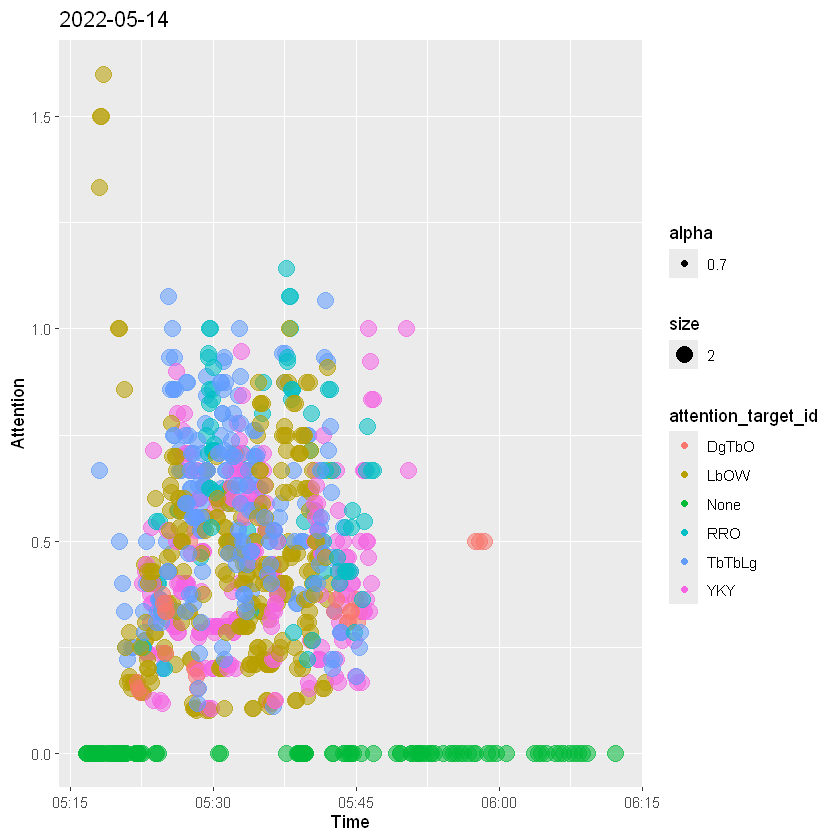

[1] "DgTbO"
[1] "KLgK"
[1] "KRDg"
[1] "LbOW"
[1] "OPR"
[1] "RbDgY"
[1] "RRO"
[1] "TbTbLg"
[1] "TbWY"
[1] "WLpTb"
[1] "YKY"


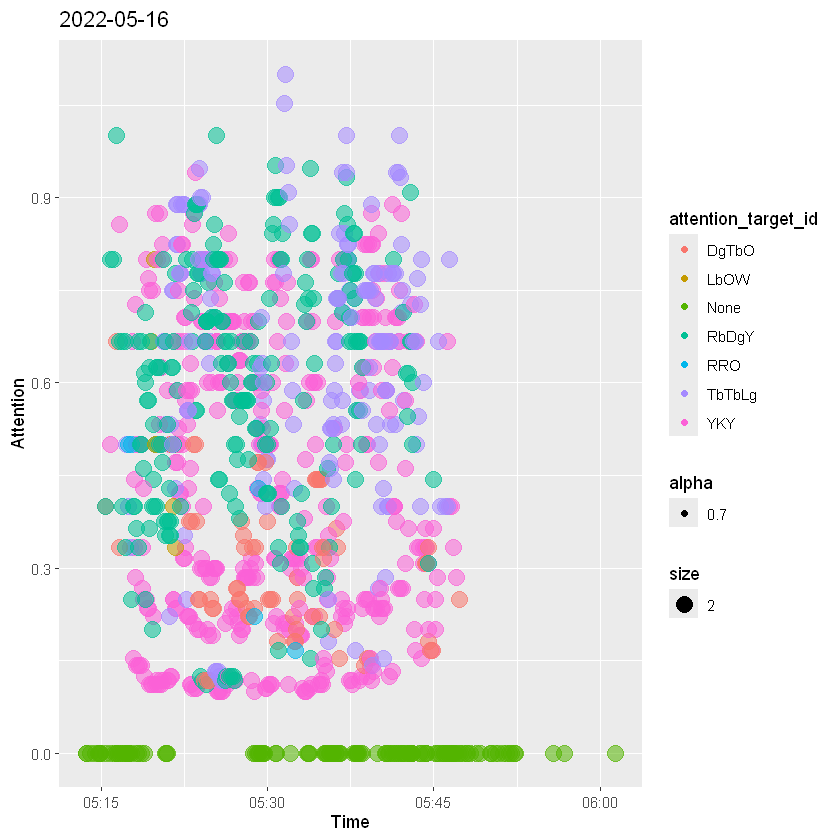

[1] "DgTbO"
[1] "KLgK"
[1] "KRDg"
[1] "LbOW"
[1] "OPR"
[1] "RbDgY"
[1] "RRO"
[1] "TbTbLg"
[1] "TbWY"
[1] "WLpTb"
[1] "YKY"


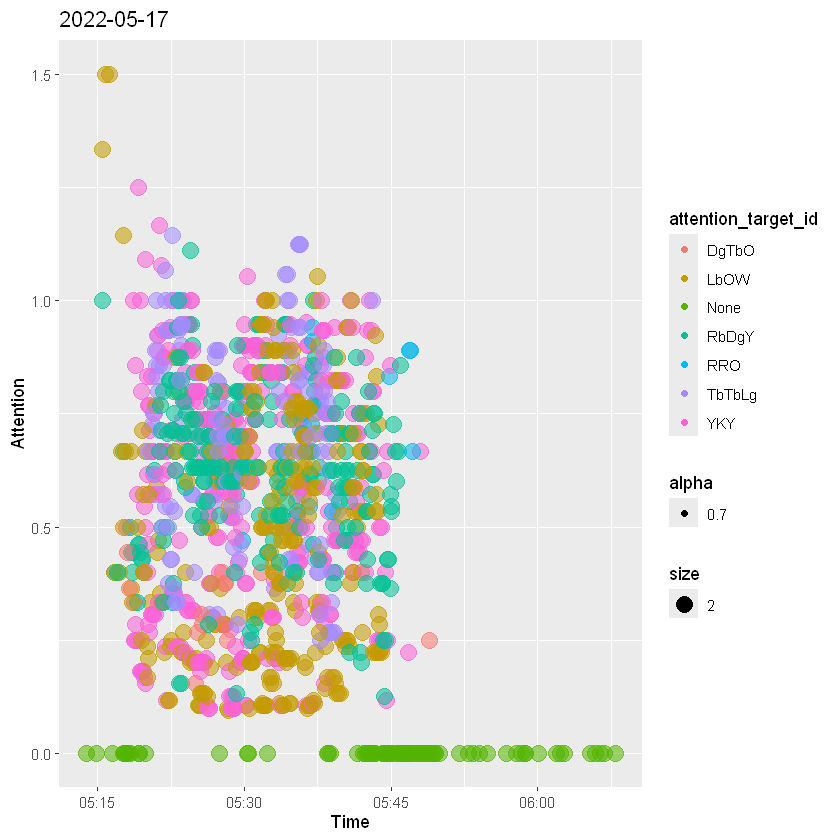

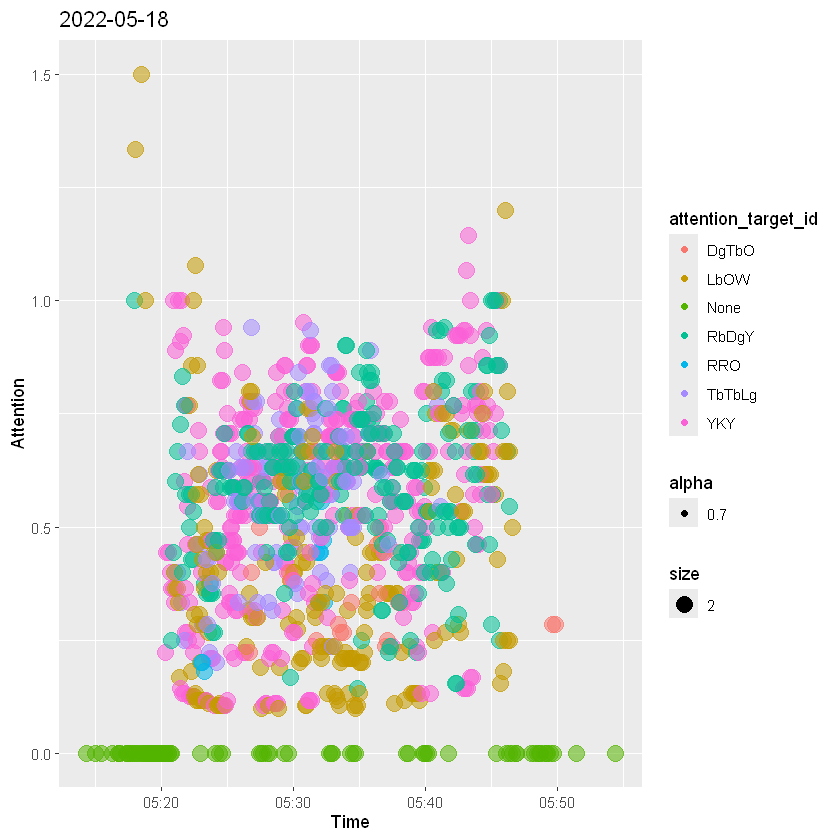

In [27]:
# Attention over time: for all focal males, who was the attention target and at what time?
dates = list("2022-05-13", "2022-05-14", "2022-05-16", "2022-05-17", "2022-05-18")
for (date in dates) {
    plt <- ggplot()
    for (id in focal_ids) {
        print(id)
        focal_data <- data_list[[id]] %>% filter(as.Date(DateTime) == date)
        plt <- plt + geom_point(data=focal_data, aes(x=DateTime, y=highest_attention, color=attention_target_id, size=2, alpha=0.7)) +
            labs(title=date, x="Time", y="Attention")
    }
    print(plt)
}


[1] "DgTbO"
[1] "KLgK"


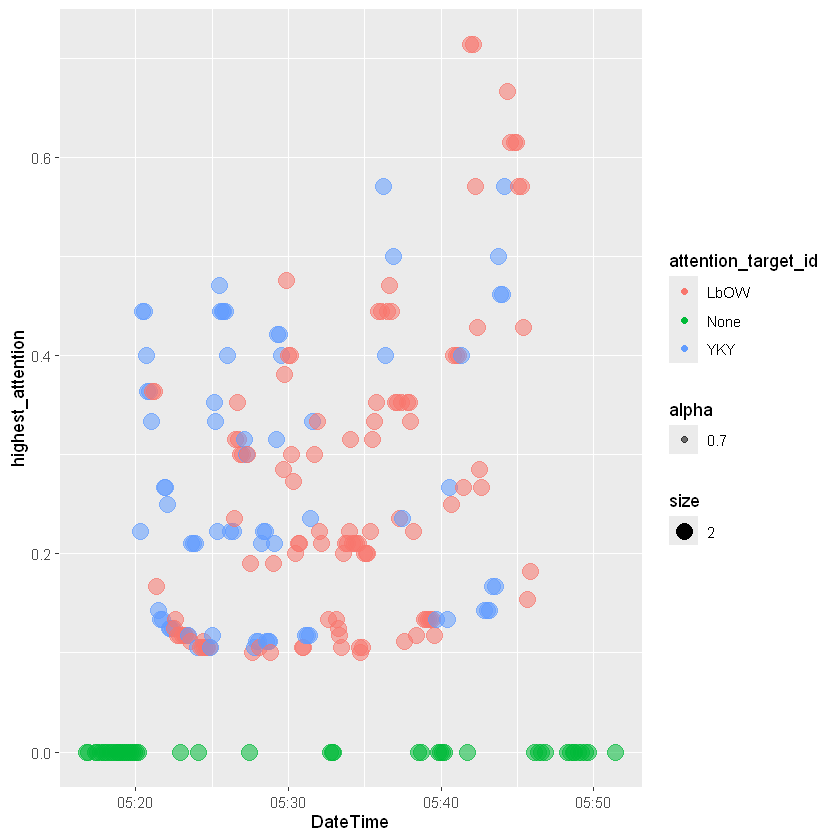

[1] "KRDg"


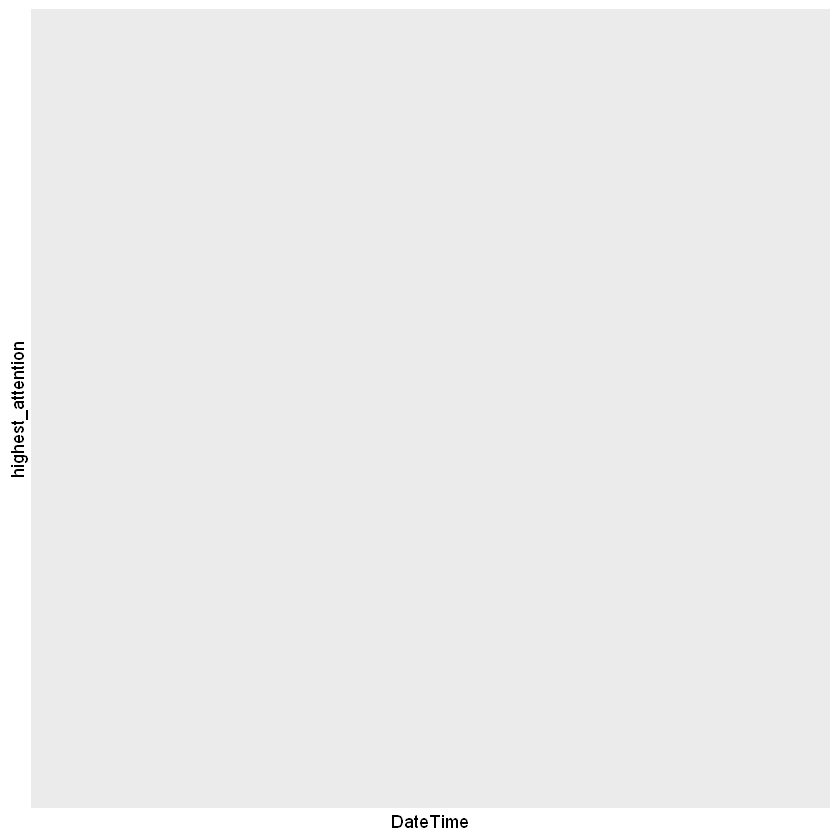

[1] "LbOW"


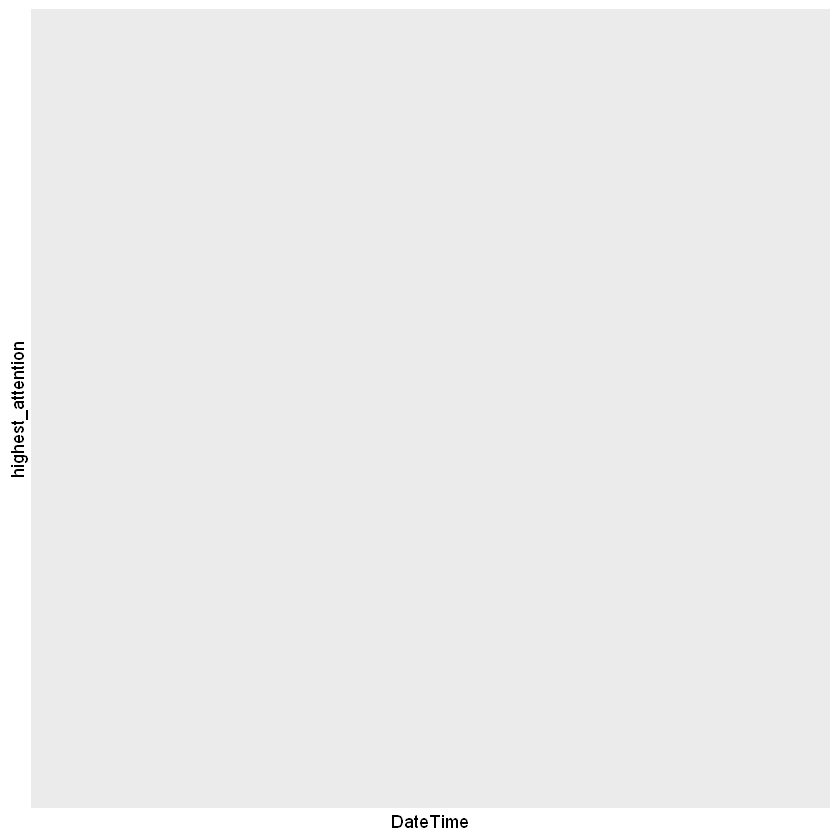

[1] "OPR"


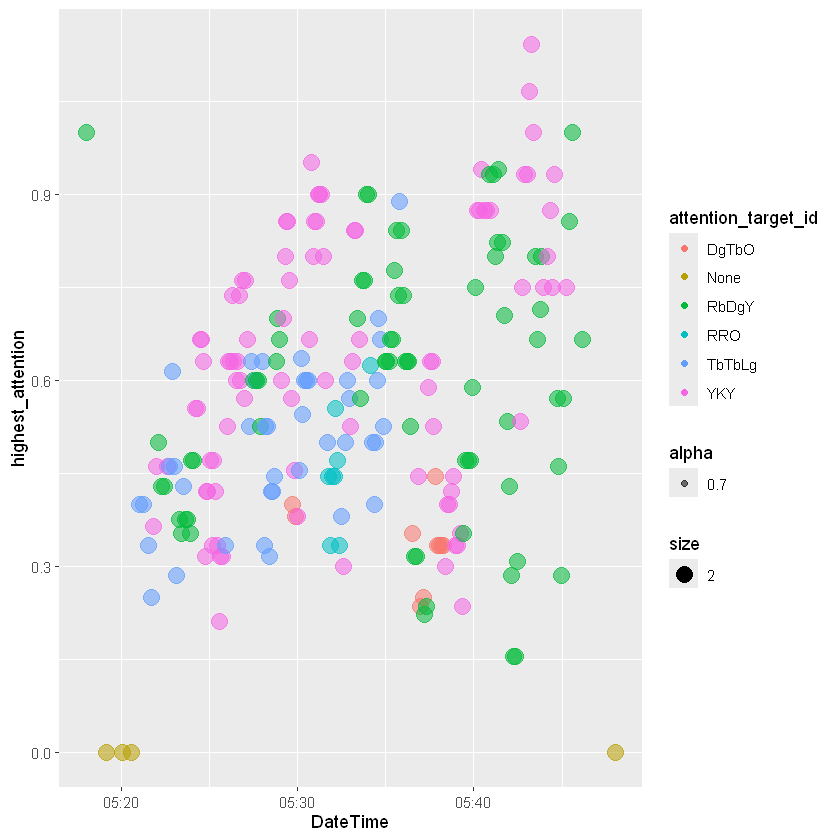

[1] "RbDgY"


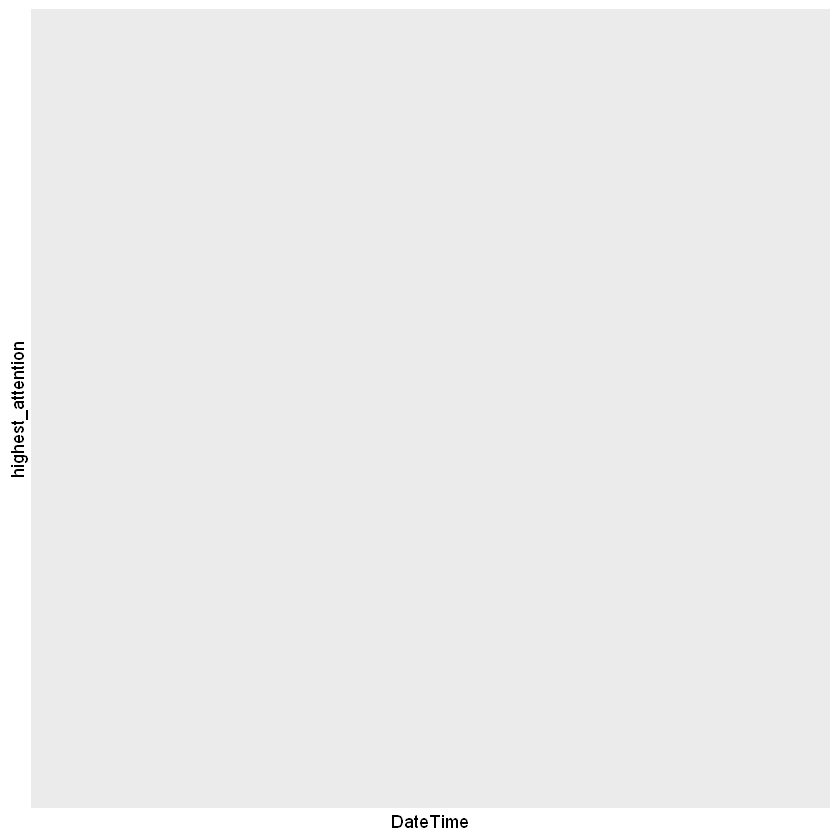

[1] "RRO"


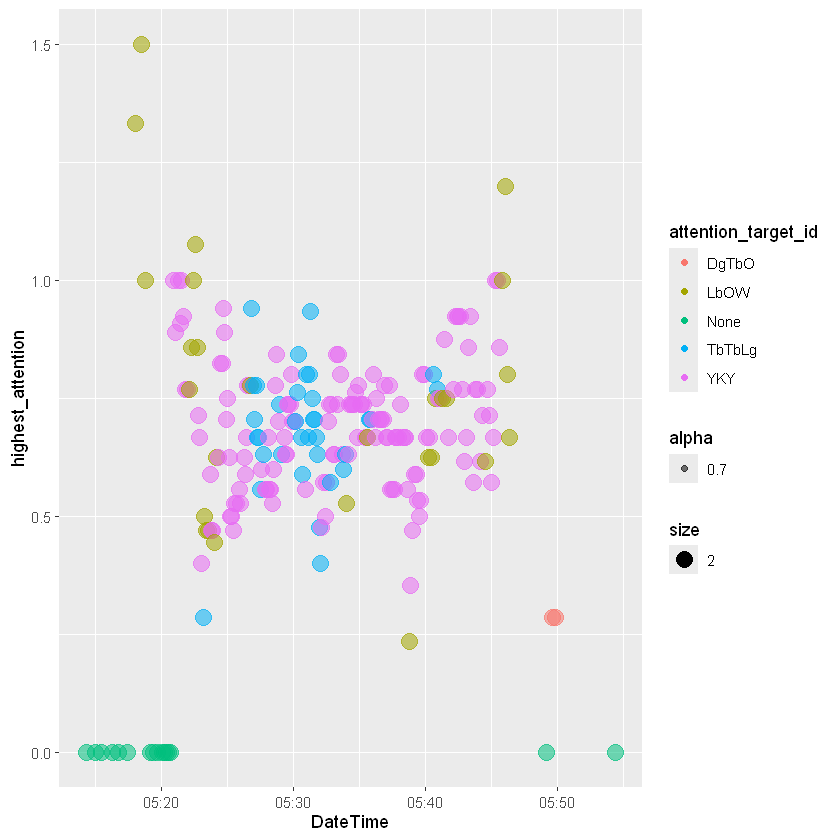

[1] "TbTbLg"


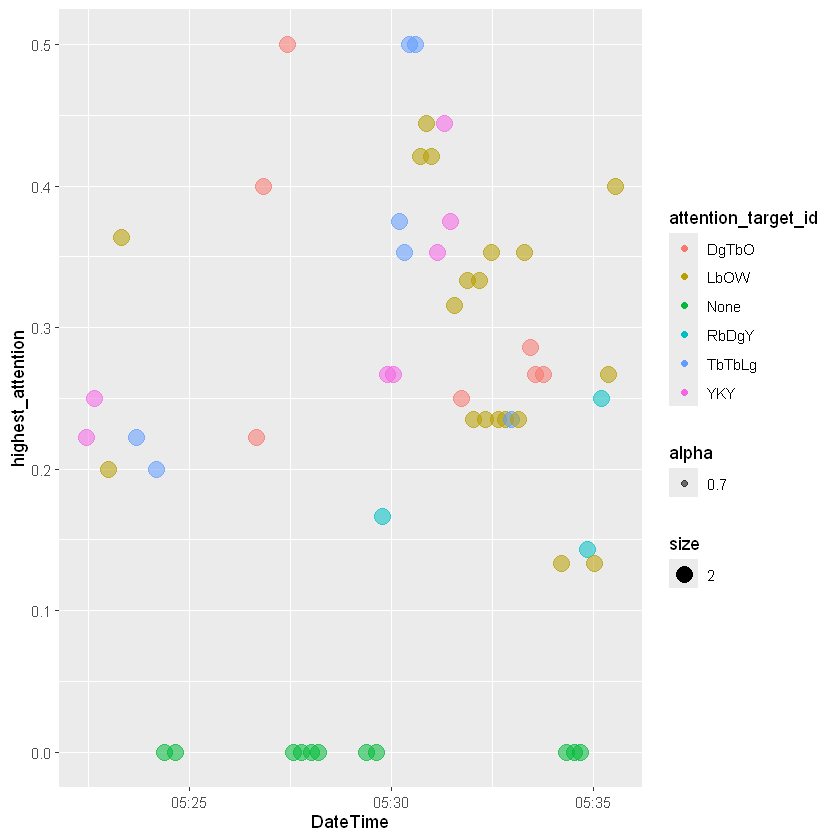

[1] "TbWY"


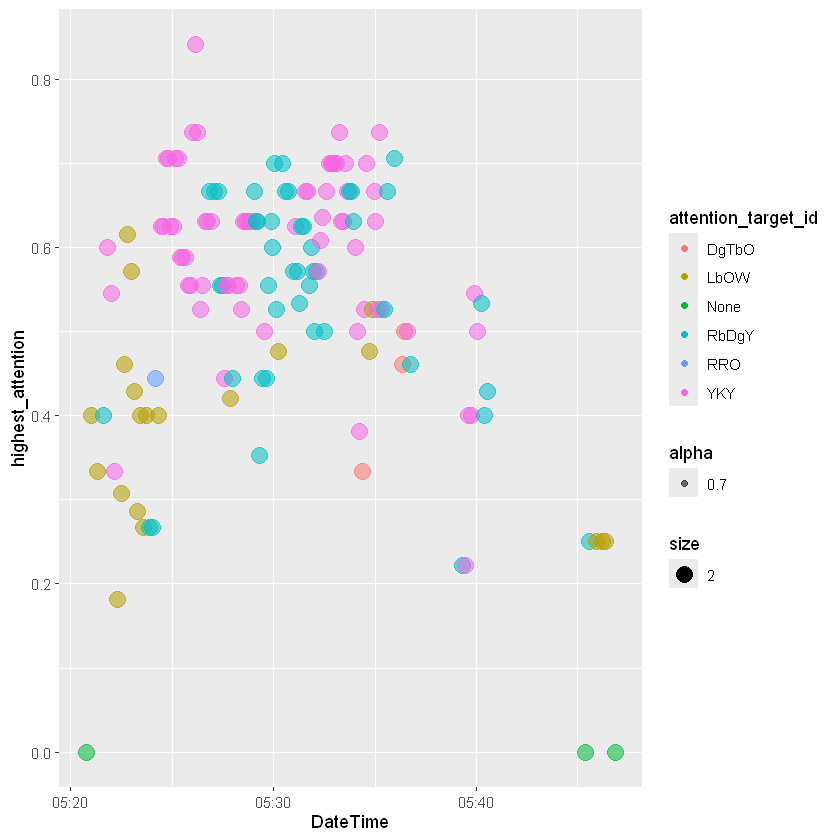

[1] "WLpTb"


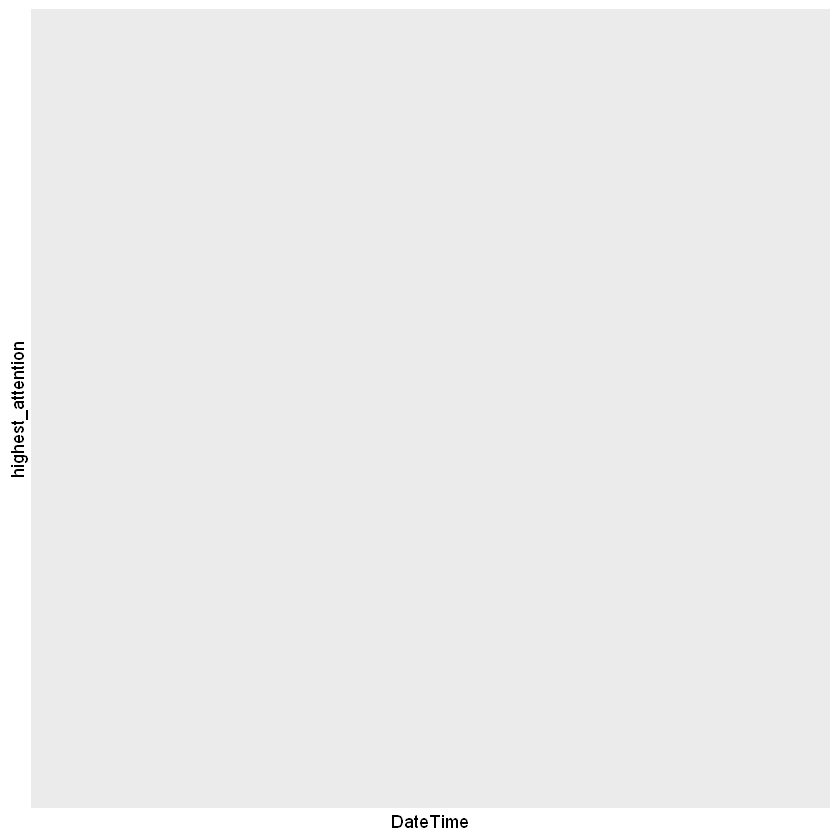

[1] "YKY"


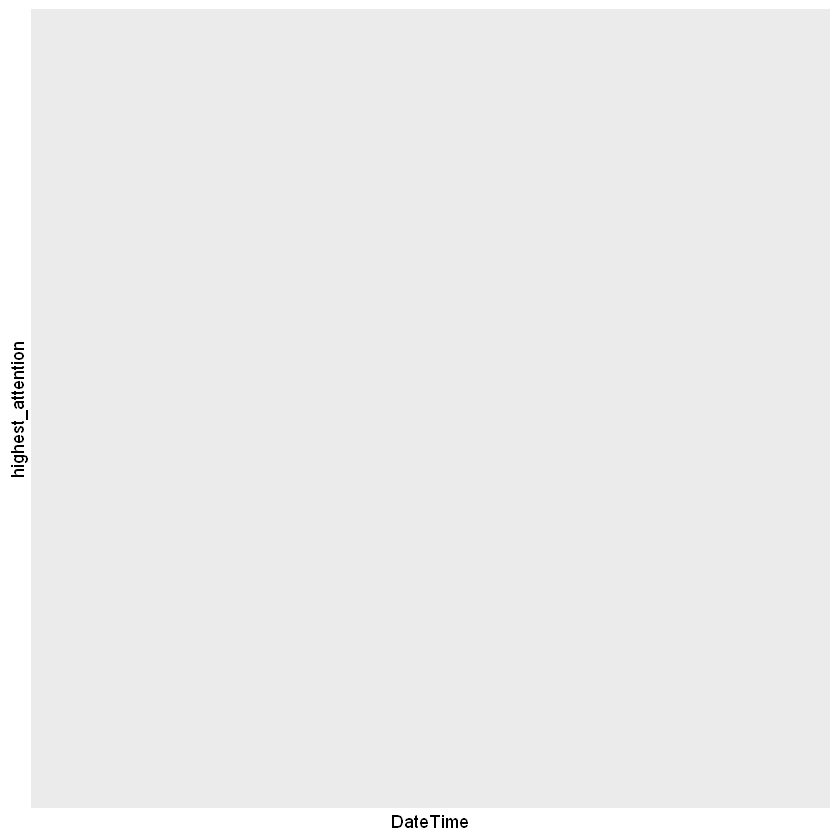

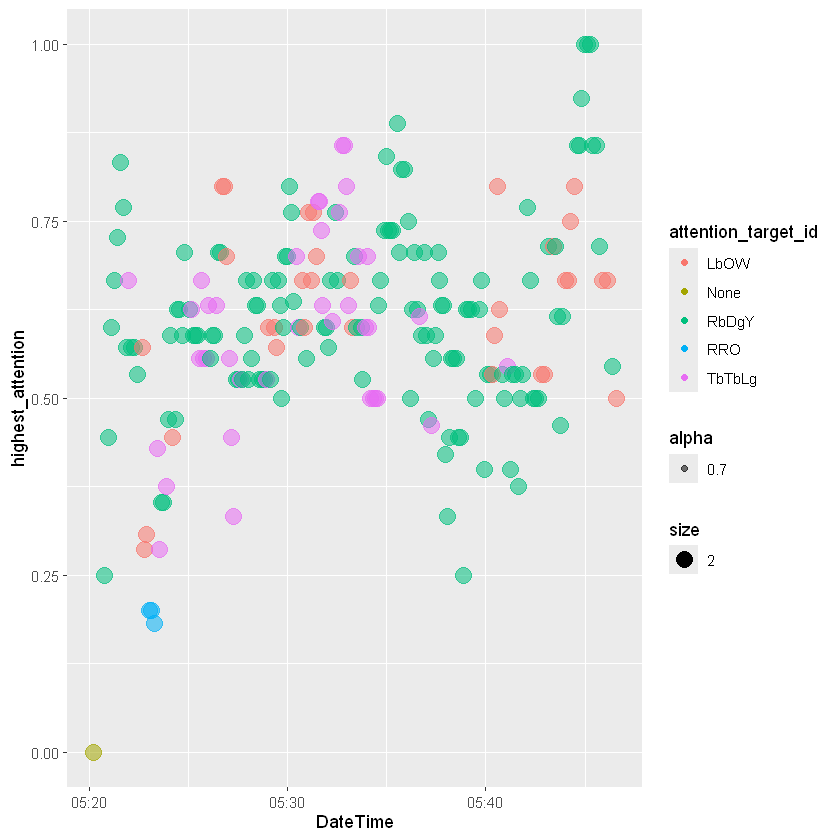

In [ ]:
# Attention over time: for each focal male, who was the attention target and at what time? ("2022-05-18")
for (id in focal_ids) {
    plt <- ggplot()
    print(id)
    focal_data <- data_list[[id]] %>% filter(as.Date(DateTime) == "2022-05-18")
    plt <- plt + geom_point(data=focal_data, aes(x=DateTime, y=highest_attention, color=attention_target_id, size=2, alpha=0.7))
    print(plt)
}

[1] "DgTbO"
[1] "KLgK"
[1] "KRDg"
[1] "LbOW"
[1] "OPR"
[1] "RbDgY"
[1] "RRO"
[1] "TbTbLg"
[1] "TbWY"
[1] "WLpTb"
[1] "YKY"


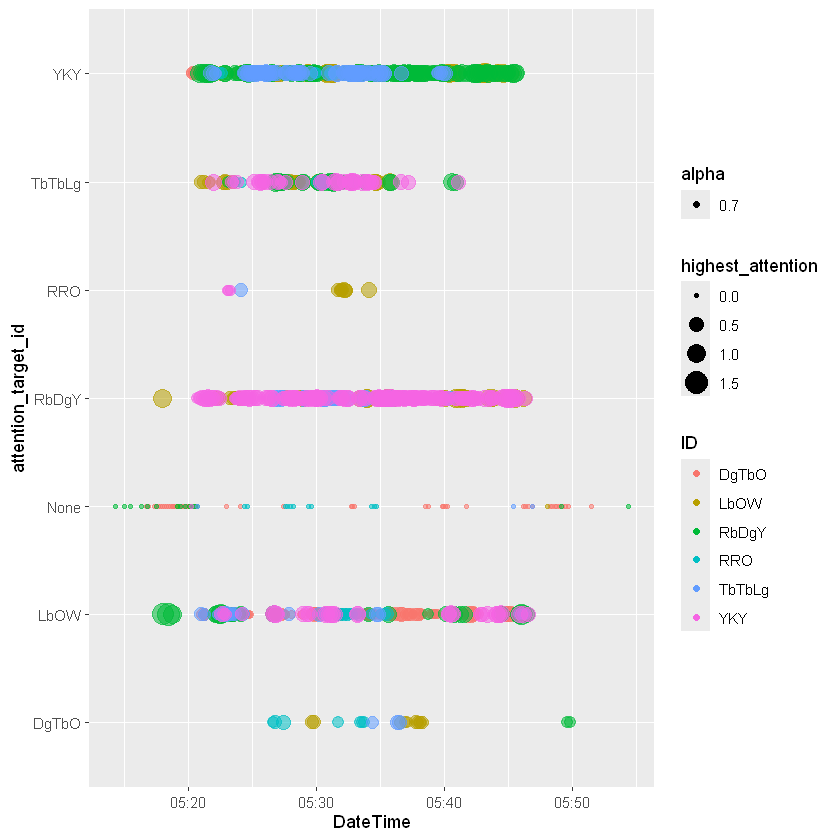

In [18]:
plt <- ggplot()
for (id in focal_ids) {
    print(id)
    focal_data <- data_list[[id]] %>% filter(as.Date(DateTime) == "2022-05-18")
    plt <- plt + geom_point(data=focal_data, aes(x=DateTime, y=attention_target_id, color=ID, size=highest_attention, alpha=0.7))
}
plt